# Understanding Convolution
This notebook explains convolution in image processing using both a numerical example and a sample image.

## Step 1 – Numerical Example (3×3 Matrix)
We start with a small 3×3 image matrix and apply a blur kernel to see how convolution works numerically.

In [1]:
import numpy as np

# Example 3x3 image matrix
I = np.array([[10, 20, 30],
              [40, 50, 60],
              [70, 80, 90]])

# Blur kernel (3x3 average filter)
K = np.ones((3,3)) / 9

# Convolution (manual calculation for center pixel)
new_value = np.mean(I)   # clearer than np.sum(I*K)
print("Original Center Pixel:", I[1,1])
print("New Center Pixel after Blur:", new_value)

Original Center Pixel: 50
New Center Pixel after Blur: 50.0


👉 This shows how convolution replaces the center pixel with the average of its neighbors.

## Step 2 – Load and Display an Image
Now let’s apply convolution to a real image.

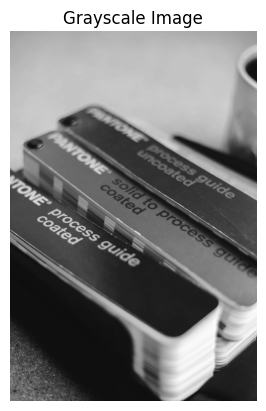

In [2]:
import cv2
import matplotlib.pyplot as plt

# Load image
img = cv2.imread('sample.jpg')   # replace with your image file
if img is None:
    raise FileNotFoundError("Image file not found. Please check the path.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')
plt.show()

## Step 3 – Define Kernels
We’ll use three kernels: blur, sharpen, and edge detection.

In [3]:
blur_kernel = np.ones((3,3), np.float32) / 9
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
edge_kernel = np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]])

## Step 4 – Apply Convolution
We apply each kernel using OpenCV’s `filter2D`.

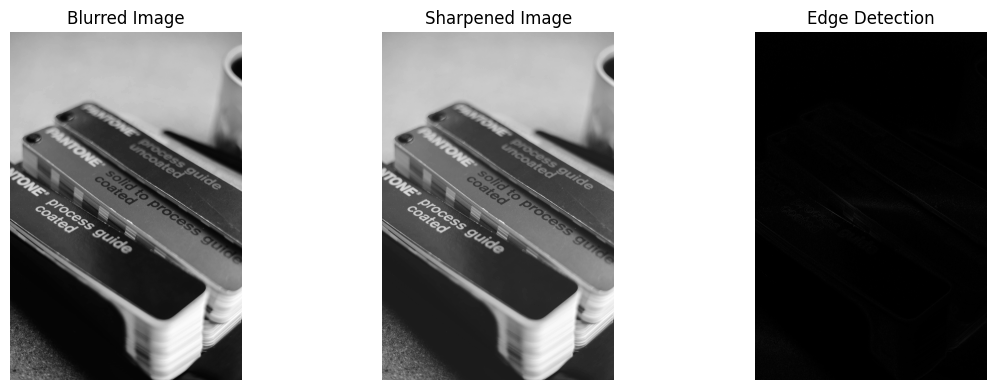

In [4]:
blurred = cv2.filter2D(gray, -1, blur_kernel)
sharpened = cv2.filter2D(gray, -1, sharpen_kernel)
edges = cv2.filter2D(gray, -1, edge_kernel)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(blurred, cmap='gray')
plt.title("Blurred Image")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(sharpened, cmap='gray')
plt.title("Sharpened Image")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(edges, cmap='gray')
plt.title("Edge Detection")
plt.axis('off')

plt.tight_layout()
plt.show()

## Step 5 – Explanation
- **Blur Kernel:** Smooths the image by averaging neighboring pixels.
- **Sharpen Kernel:** Enhances fine details and edges.
- **Edge Kernel:** Highlights boundaries where pixel intensity changes sharply.

👉 Convolution is simply sliding these kernels across the image and combining pixel values according to the kernel pattern.

💡 Note: Convolution is also the foundation of Convolutional Neural Networks (CNNs), where kernels are learned automatically.